In [1]:
# import modules
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from scipy import stats
import phik
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import chi2

#install and import other necessary tools
from ydata_profiling import ProfileReport

# For VIF Test
from statsmodels.stats.outliers_influence import variance_inflation_factor 




C:\Users\DELL\AppData\Local\Temp\ipykernel_4972\432077714.py:13: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


In [2]:
# open the dataset
df = pd.read_csv('real_estate_dataset.csv')
df.head()

,ID,Square_Feet,Num_Bedrooms,Num_Bathrooms,Num_Floors,Year_Built,Has_Garden,Has_Pool,Garage_Size,Location_Score,Distance_to_Center,Price
0,1,143.635030,1,3,3,1967,1,1,48,8.297631,5.935734,602134.816747
1,2,287.678577,1,2,1,1949,0,1,37,6.061466,10.827392,591425.135386
2,3,232.998485,1,3,2,1923,1,0,14,2.911442,6.904599,464478.696880
3,4,199.664621,5,2,2,1918,0,0,17,2.070949,8.284019,583105.655996
4,5,89.004660,4,3,3,1999,1,0,34,1.523278,14.648277,619879.142523


In [3]:
# We do not need ID column
df = df.drop("ID", axis = 1)
df.head()

,Square_Feet,Num_Bedrooms,Num_Bathrooms,Num_Floors,Year_Built,Has_Garden,Has_Pool,Garage_Size,Location_Score,Distance_to_Center,Price
0,143.635030,1,3,3,1967,1,1,48,8.297631,5.935734,602134.816747
1,287.678577,1,2,1,1949,0,1,37,6.061466,10.827392,591425.135386
2,232.998485,1,3,2,1923,1,0,14,2.911442,6.904599,464478.696880
3,199.664621,5,2,2,1918,0,0,17,2.070949,8.284019,583105.655996
4,89.004660,4,3,3,1999,1,0,34,1.523278,14.648277,619879.142523


In [4]:
# Generate the data profiling report, title is just for viewing purposes
report = ProfileReport(df,
    title='Real_State Housing Data, Data Engineering / Advanced Data Analytics, 2026'
)

# create the report into a separate HTML -file
# you could send this HTML-file to your colleaque 
# and it should work!
report.to_file("ydata_housing_regression_report.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 11/11 [00:00<00:00, 637.56it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [5]:
# See the data types
df.dtypes

Square_Feet           float64
Num_Bedrooms            int64
Num_Bathrooms           int64
Num_Floors              int64
Year_Built              int64
Has_Garden              int64
Has_Pool                int64
Garage_Size             int64
Location_Score        float64
Distance_to_Center    float64
Price                 float64
dtype: object

### Check the data evaluation using Autoviz


In [6]:
from autoviz.AutoViz_Class import AutoViz_Class
AV = AutoViz_Class()
report = AV.AutoViz(df)

Imported v0.1.905. Please call AutoViz in this sequence:
    AV = AutoViz_Class()
    %matplotlib inline
    dfte = AV.AutoViz(filename, sep=',', depVar='', dfte=None, header=0, verbose=1, lowess=False,
               chart_format='svg',max_rows_analyzed=150000,max_cols_analyzed=30, save_plot_dir=None)
Shape of your Data Set loaded: (500, 11)
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
    Number of Numeric Columns =  4
    Number of Integer-Categorical Columns =  4
    Number of String-Categorical Columns =  0
    Number of Factor-Categorical Columns =  0
    Number of String-Boolean Columns =  0
    Number of Numeric-Boolean Columns =  2
    Number of Discrete String Columns =  0
    Number of NLP String Columns =  0
    Number of 

,Data Type,Missing Values%,Unique Values%,Minimum Value,Maximum Value,DQ Issue
Square_Feet,float64,0.000000,NA,51.265396,298.241199,No issue
Num_Bedrooms,int64,0.000000,1,1.000000,5.000000,No issue
Num_Bathrooms,int64,0.000000,0,1.000000,3.000000,No issue
Num_Floors,int64,0.000000,0,1.000000,3.000000,No issue
Year_Built,int64,0.000000,24,1900.000000,2022.000000,Possible date-time colum: transform before modeling step.
Has_Garden,int64,0.000000,0,0.000000,1.000000,No issue
Has_Pool,int64,0.000000,0,0.000000,1.000000,No issue
Garage_Size,int64,0.000000,8,10.000000,49.000000,No issue
Location_Score,float64,0.000000,NA,0.004428,9.995439,No issue
Distance_to_Center,float64,0.000000,NA,0.062818,19.927966,No issue


Number of All Scatter Plots = 10
All Plots done
Time to run AutoViz = 2 seconds 

 ###################### AUTO VISUALIZATION Completed ########################


In [7]:
from bokeh.io import output_notebook
output_notebook()

Loading BokehJS ...

In [8]:
    # pip install autoviz
    # pip install jinja2==3.1.2
    # pip install jupyter_bokeh
    from autoviz.AutoViz_Class import AutoViz_Class
    AV = AutoViz_Class()
    report = AV.AutoViz("real_estate_dataset.csv", chart_format="bokeh", depVar="Price")
    report

Shape of your Data Set loaded: (500, 12)
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
    Number of Numeric Columns =  3
    Number of Integer-Categorical Columns =  4
    Number of String-Categorical Columns =  0
    Number of Factor-Categorical Columns =  0
    Number of String-Boolean Columns =  0
    Number of Numeric-Boolean Columns =  2
    Number of Discrete String Columns =  0
    Number of NLP String Columns =  0
    Number of Date Time Columns =  1
    Number of ID Columns =  1
    Number of Columns to Delete =  0
    11 Predictors classified...
        1 variable(s) removed since they were ID or low-information variables
        List of variables removed: ['ID']

################ Regression problem #####################


BokehModel(combine_events=True, render_bundle={'docs_json': {'b6bee805-d309-4092-8227-5a6891fcbb04': {'version…

BokehModel(combine_events=True, render_bundle={'docs_json': {'0b423aec-1145-4e9f-9de1-3bf5ecbe7cf5': {'version…

BokehModel(combine_events=True, render_bundle={'docs_json': {'09f8fd5b-868b-4164-a7a0-21313cfa014a': {'version…

BokehModel(combine_events=True, render_bundle={'docs_json': {'b1a9dd92-c1f3-4a05-8045-56447e9c12df': {'version…

BokehModel(combine_events=True, render_bundle={'docs_json': {'60215d1e-5473-49aa-ba21-f6531134acd2': {'version…

BokehModel(combine_events=True, render_bundle={'docs_json': {'49328ff1-c15b-419b-ac18-883acc052e28': {'version…

BokehModel(combine_events=True, render_bundle={'docs_json': {'1c43f4b5-9448-4538-b466-c93334d67927': {'version…

BokehModel(combine_events=True, render_bundle={'docs_json': {'b692a26f-165e-494a-803b-640ec8672429': {'version…

BokehModel(combine_events=True, render_bundle={'docs_json': {'bcfcbca9-e143-46a5-b51e-df6b352474ac': {'version…

Time to run AutoViz (in seconds) = 5


,Square_Feet,Num_Bedrooms,Num_Bathrooms,Num_Floors,Year_Built,Has_Garden,Has_Pool,Garage_Size,Location_Score,Distance_to_Center,Price
0,143.635030,1,3,3,1967,1,1,48,8.297631,5.935734,602134.816747
1,287.678577,1,2,1,1949,0,1,37,6.061466,10.827392,591425.135386
2,232.998485,1,3,2,1923,1,0,14,2.911442,6.904599,464478.696880
3,199.664621,5,2,2,1918,0,0,17,2.070949,8.284019,583105.655996
4,89.004660,4,3,3,1999,1,0,34,1.523278,14.648277,619879.142523
5,88.998630,5,3,2,1959,1,1,36,8.994552,17.633250,670386.804433
6,64.520903,4,3,1,1938,0,1,32,7.101354,2.429908,523827.125601
7,266.544036,5,1,3,1973,1,1,39,9.373784,12.692785,875352.545188
8,200.278753,5,1,1,1988,1,1,32,6.032918,11.642876,738269.852342
9,227.018144,3,2,1,1917,0,0,29,4.734009,2.368301,490552.681240


In [9]:
# Quickly check the outlier row of the price
df[(df['Price'] > 910235) | (df['Price'] < 258787)]


,Square_Feet,Num_Bedrooms,Num_Bathrooms,Num_Floors,Year_Built,Has_Garden,Has_Pool,Garage_Size,Location_Score,Distance_to_Center,Price
150,277.066471,5,2,3,2019,1,1,30,9.037576,13.094182,960678.274291


#### Optional  : Visualization using Q-Q plots


In [10]:
df = pd.read_csv('real_estate_dataset.csv')
df = df.drop("ID", axis = 1)
df.head()


,Square_Feet,Num_Bedrooms,Num_Bathrooms,Num_Floors,Year_Built,Has_Garden,Has_Pool,Garage_Size,Location_Score,Distance_to_Center,Price
0,143.635030,1,3,3,1967,1,1,48,8.297631,5.935734,602134.816747
1,287.678577,1,2,1,1949,0,1,37,6.061466,10.827392,591425.135386
2,232.998485,1,3,2,1923,1,0,14,2.911442,6.904599,464478.696880
3,199.664621,5,2,2,1918,0,0,17,2.070949,8.284019,583105.655996
4,89.004660,4,3,3,1999,1,0,34,1.523278,14.648277,619879.142523


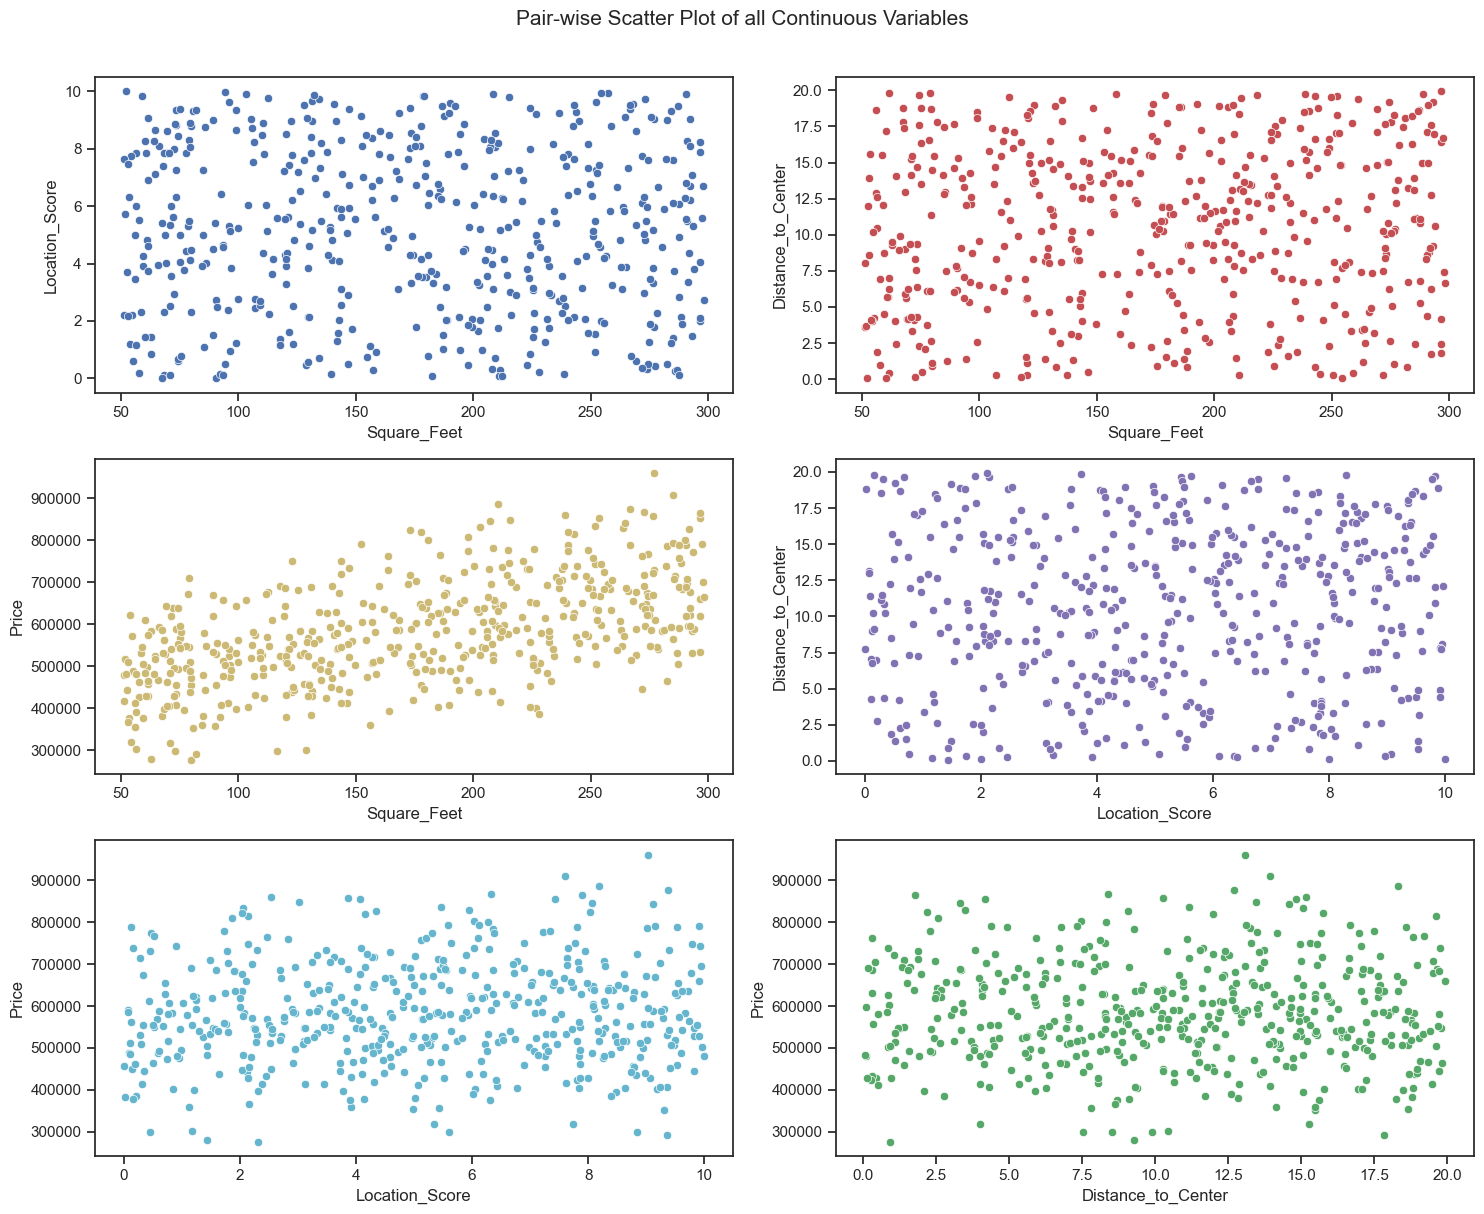

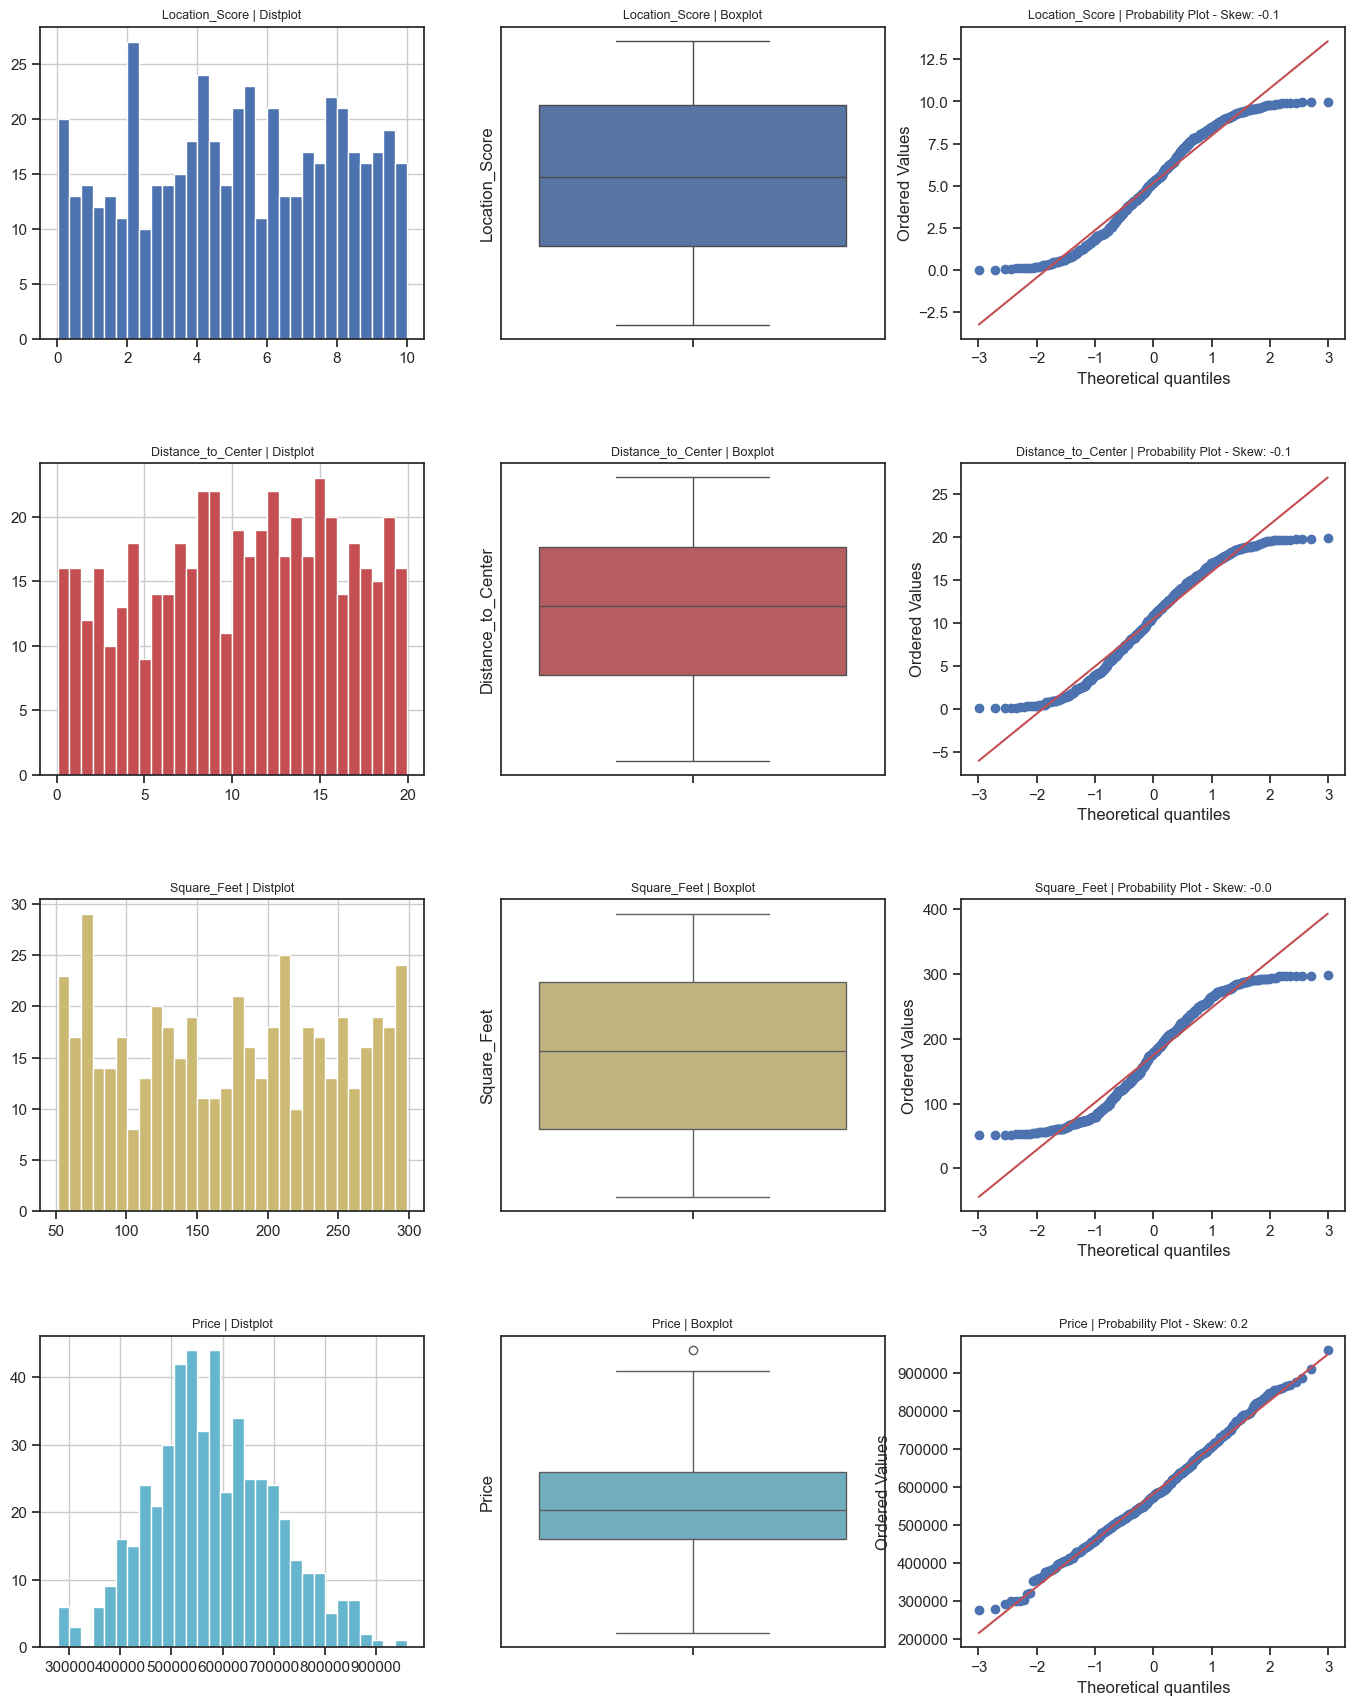

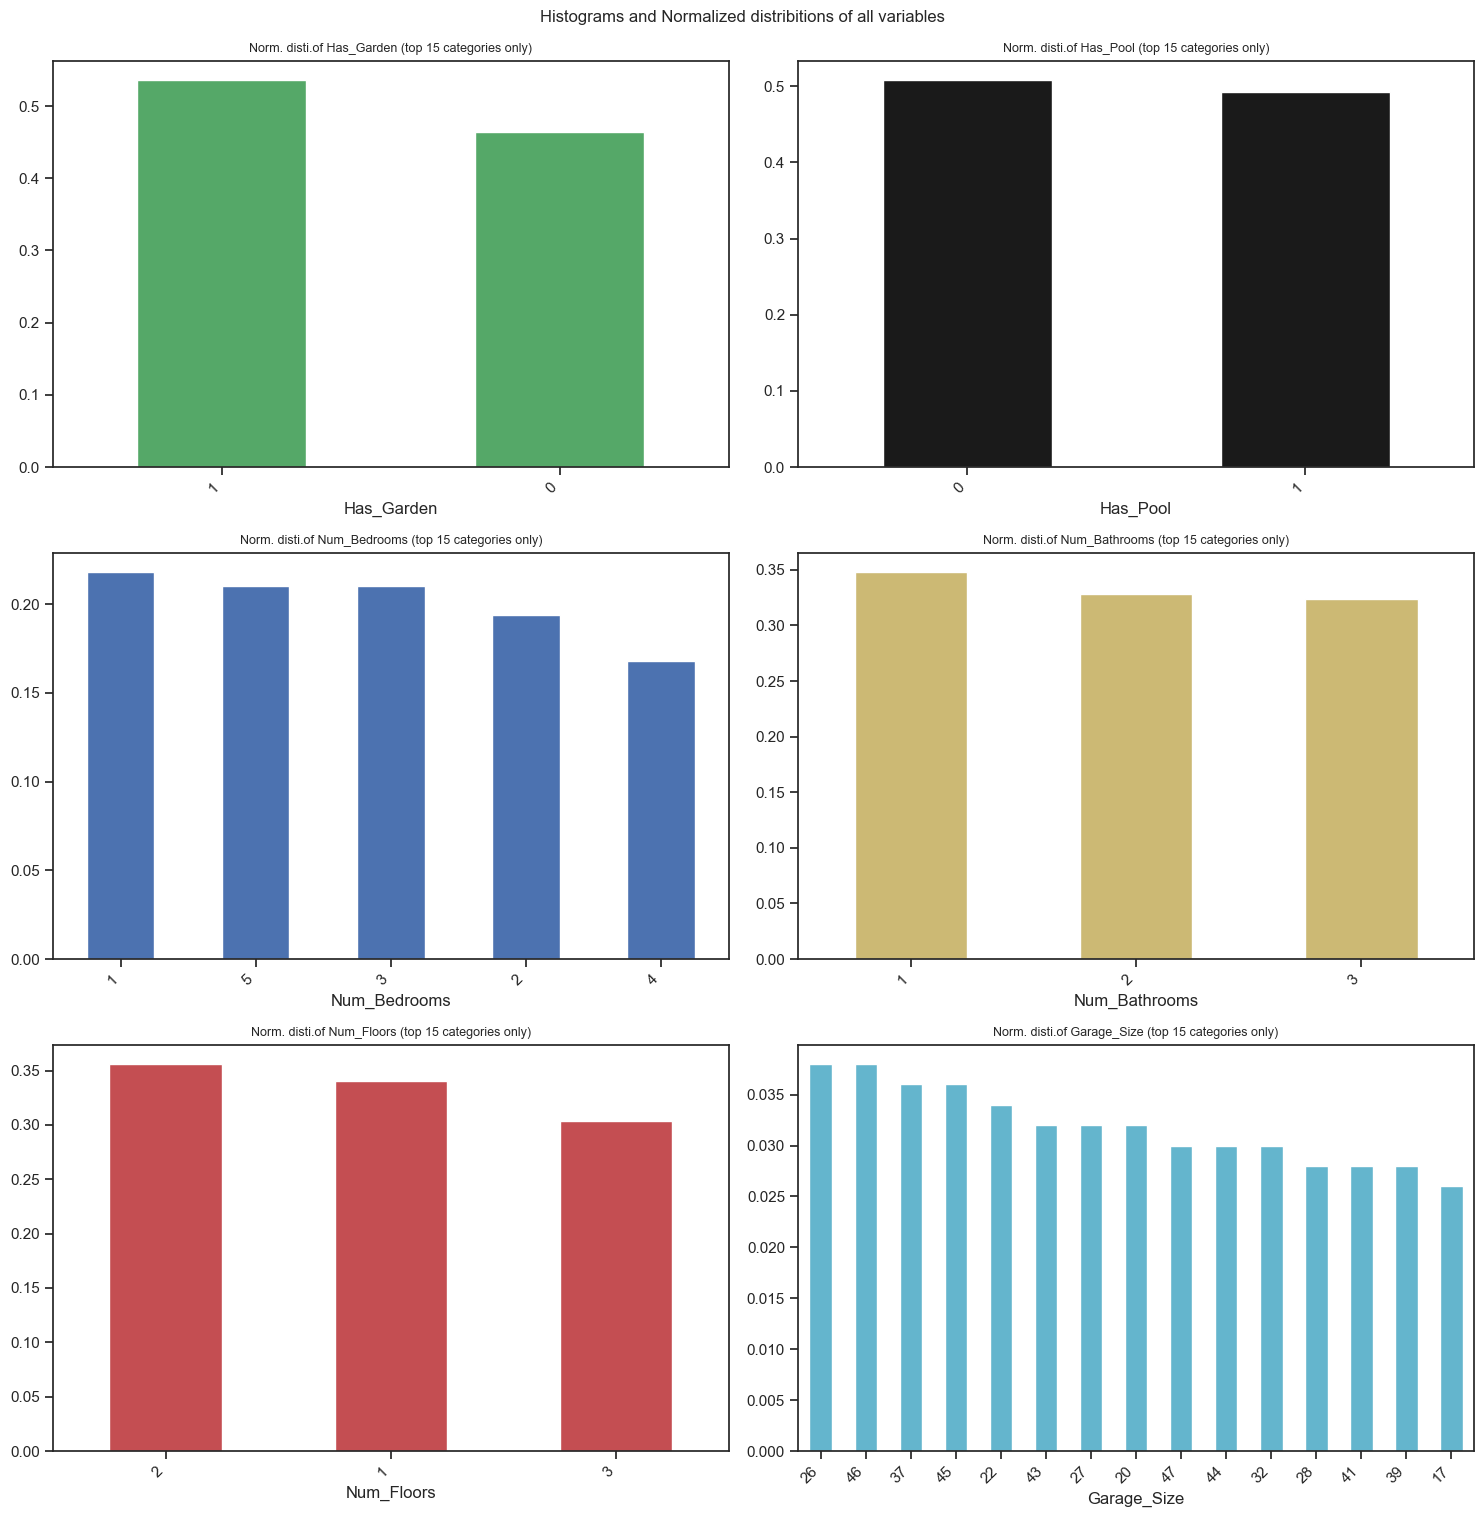

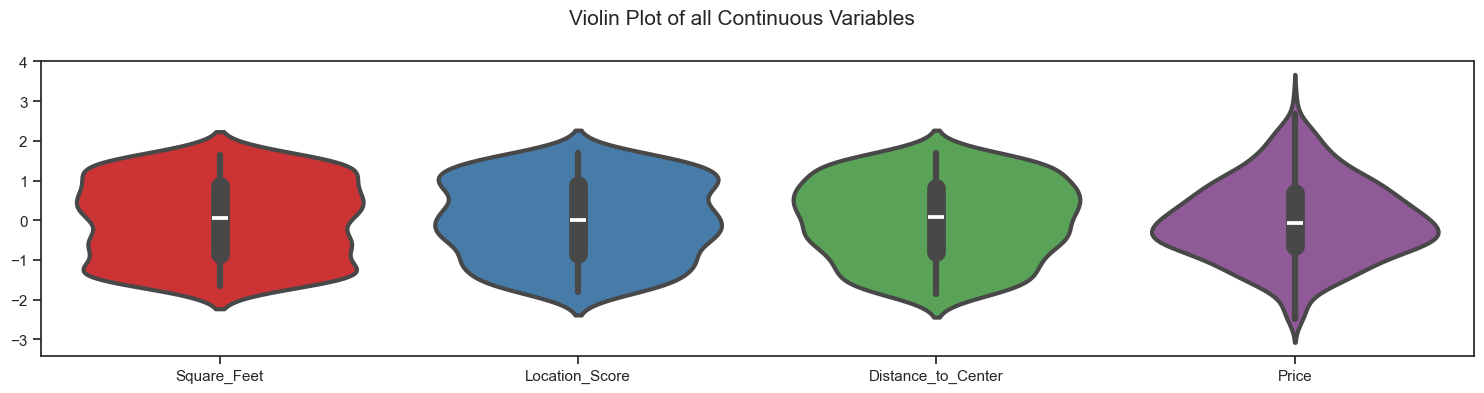

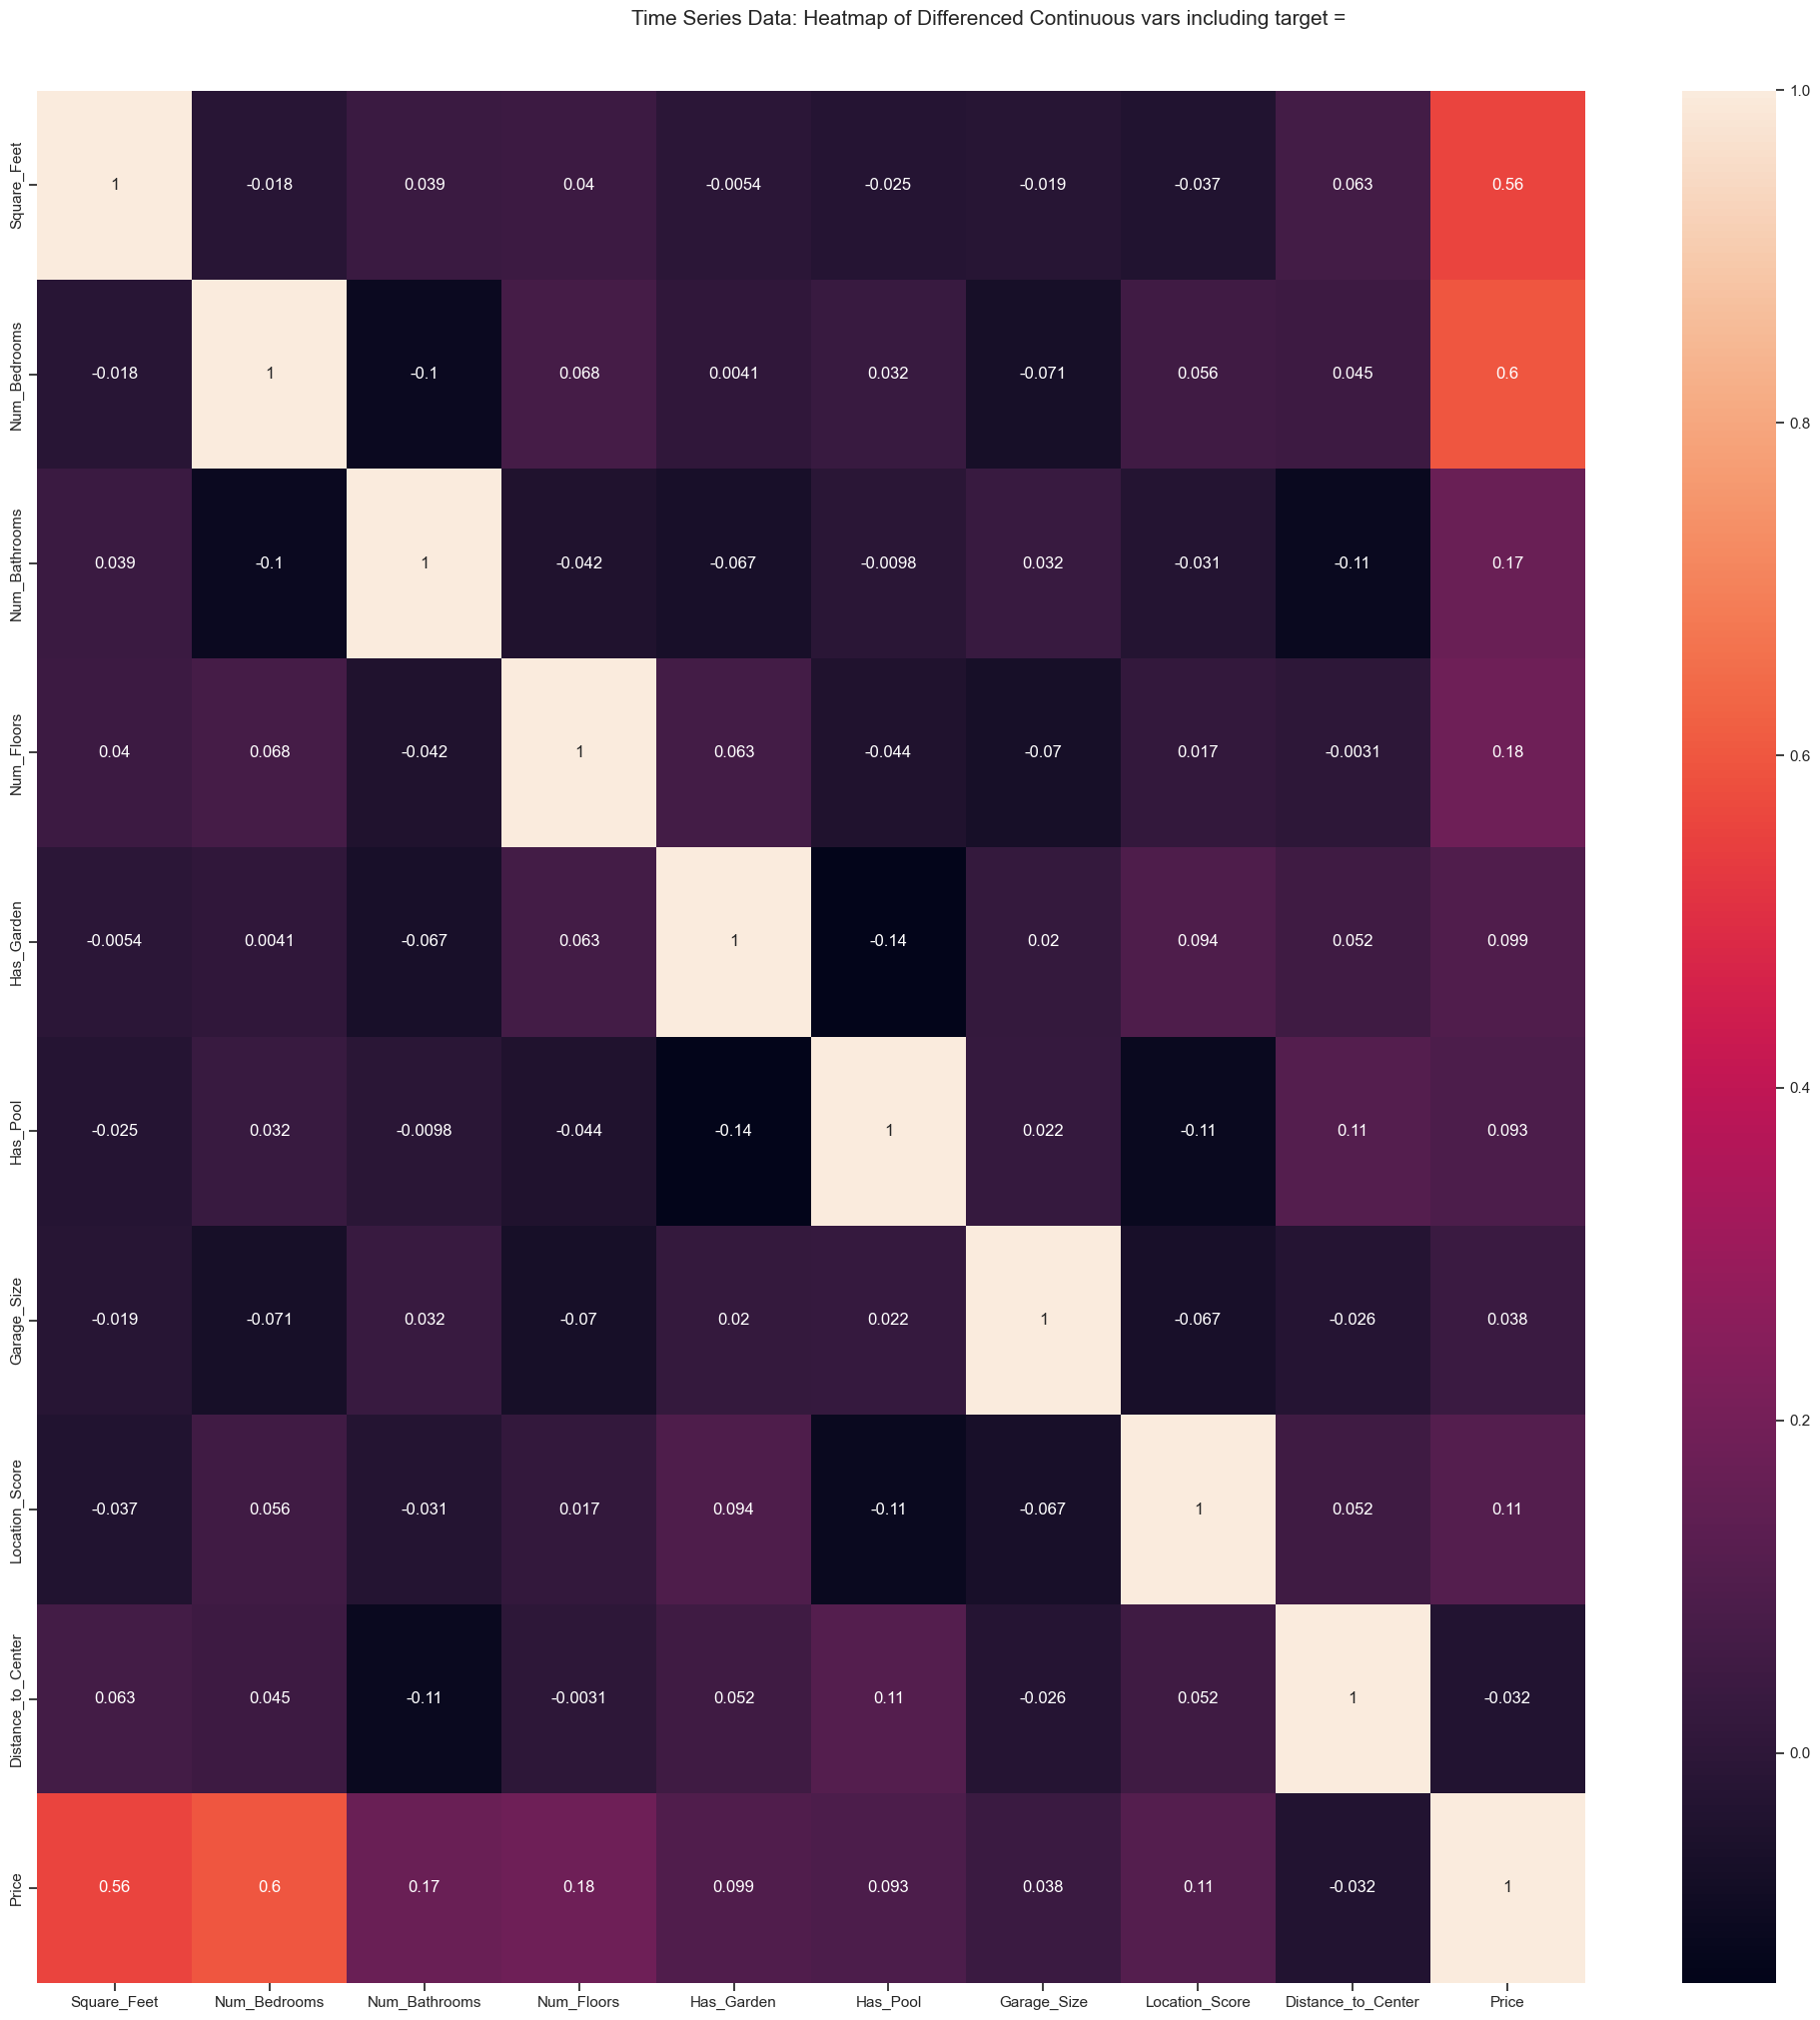

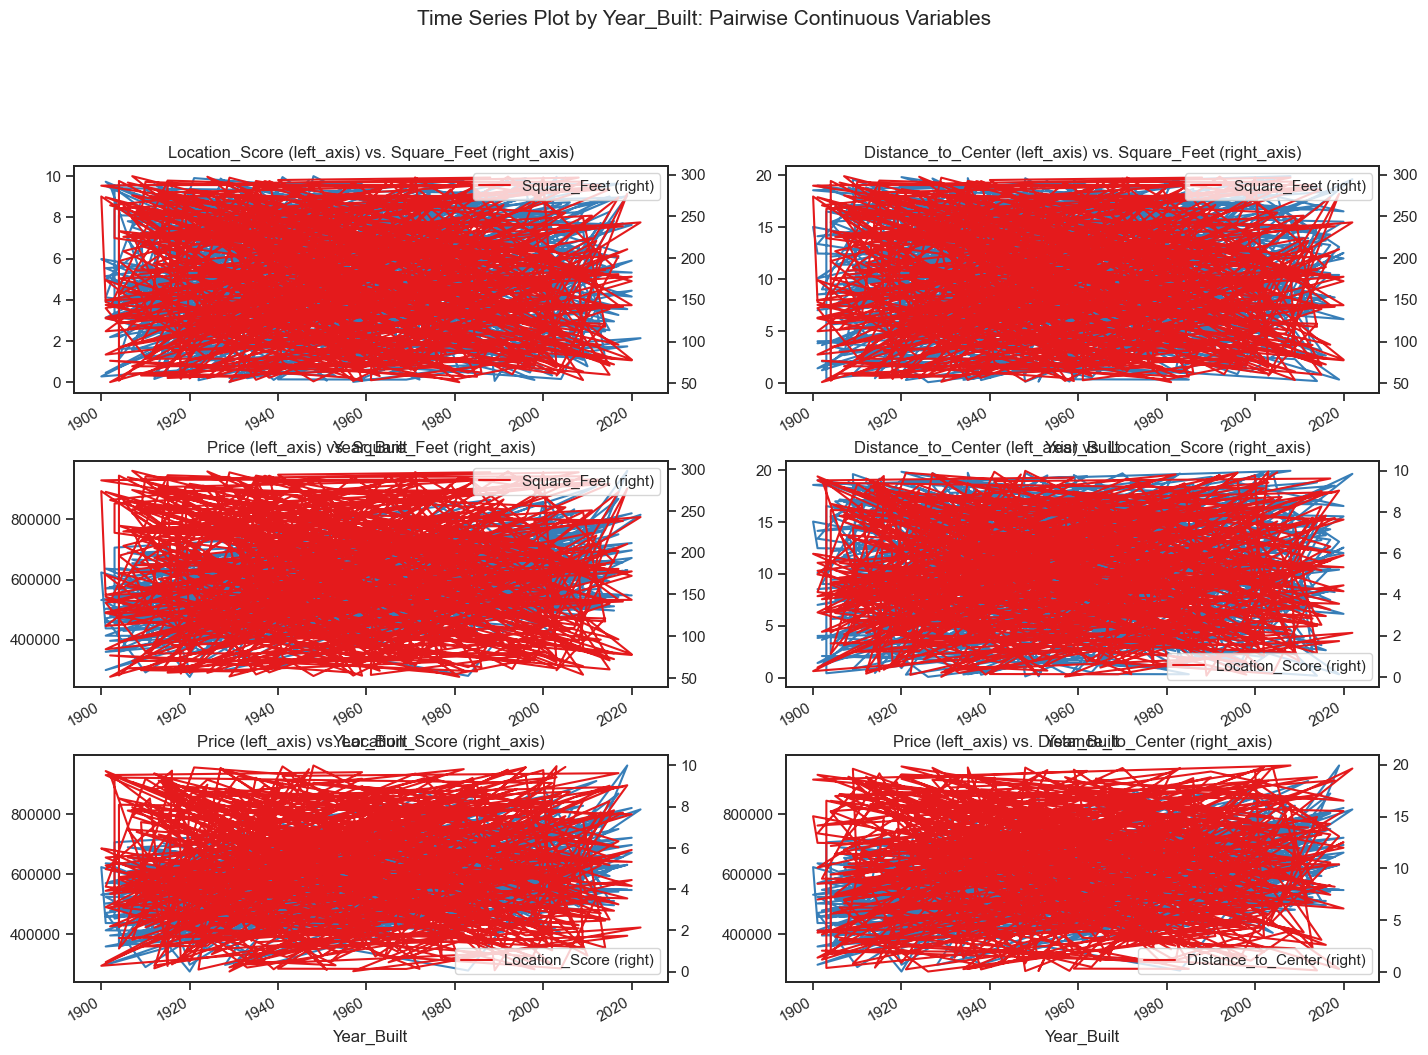

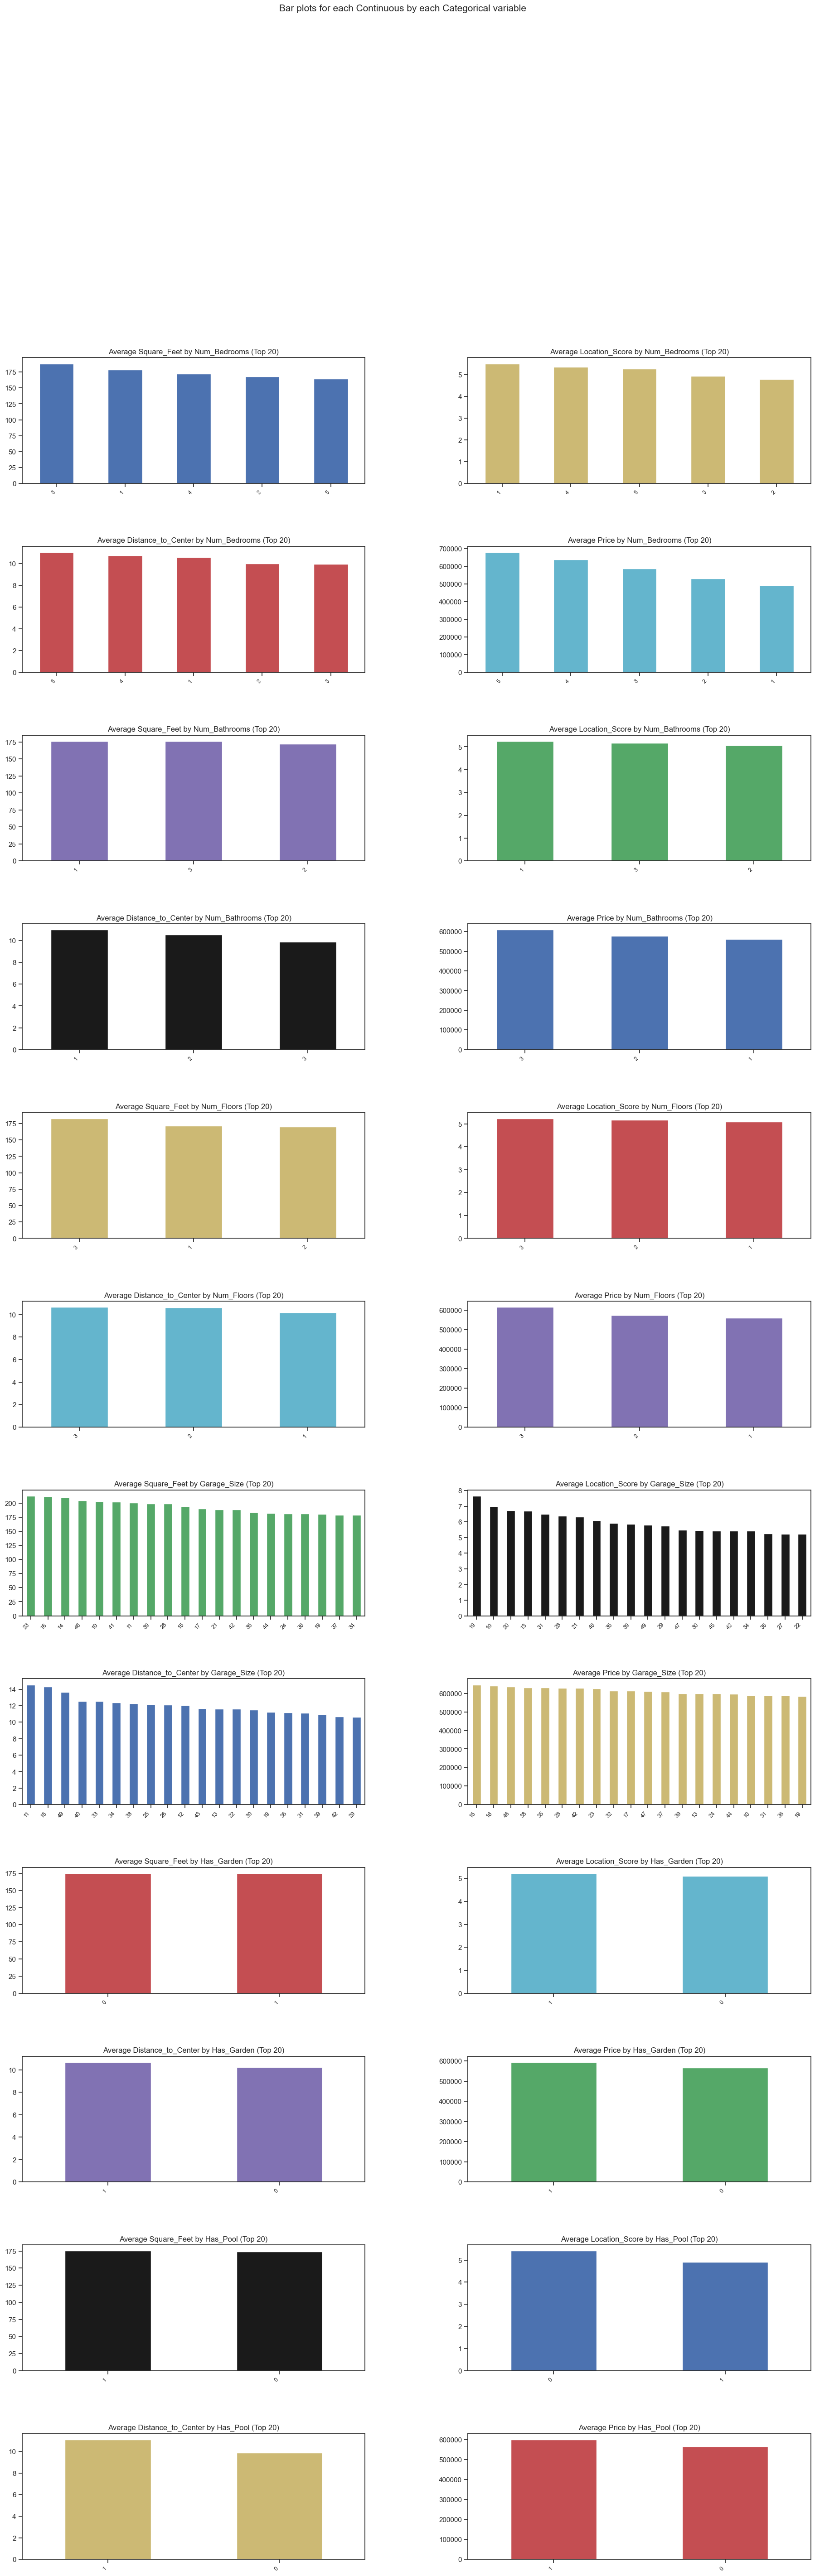

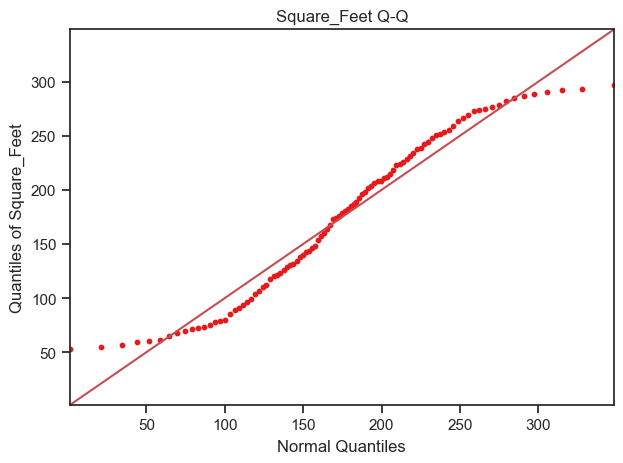

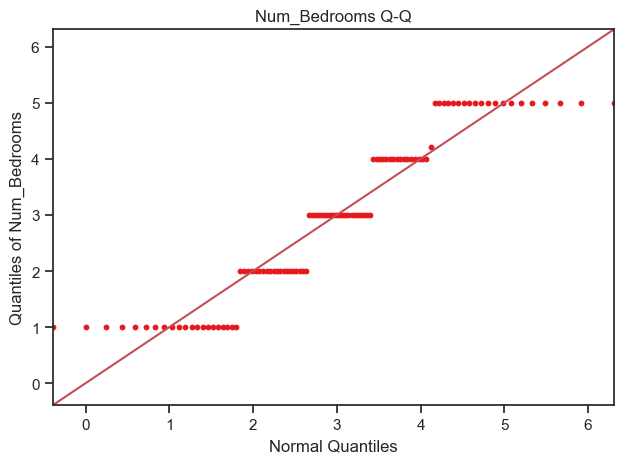

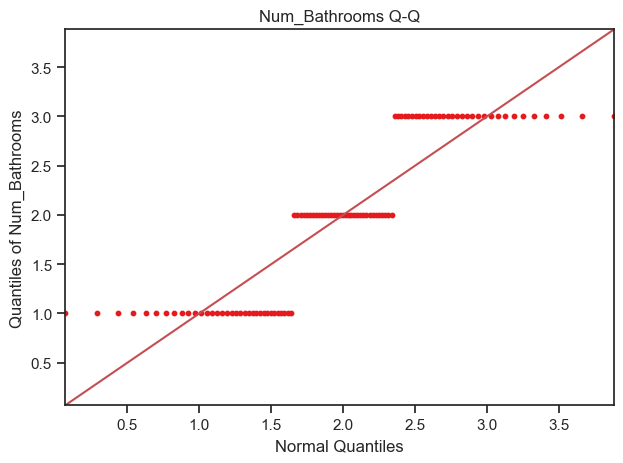

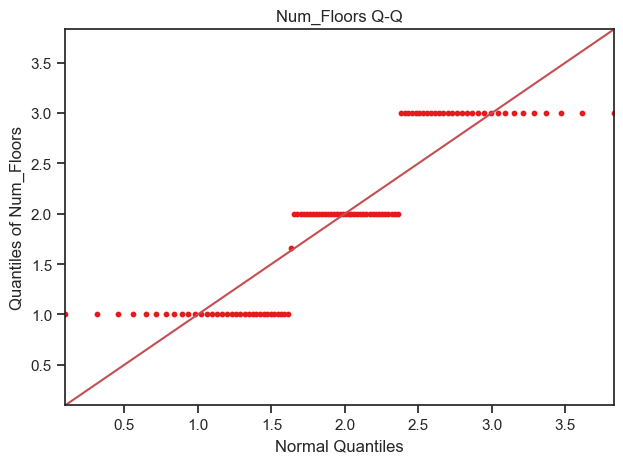

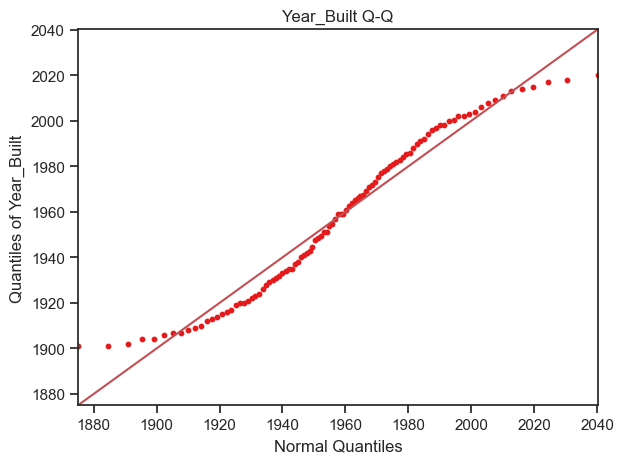

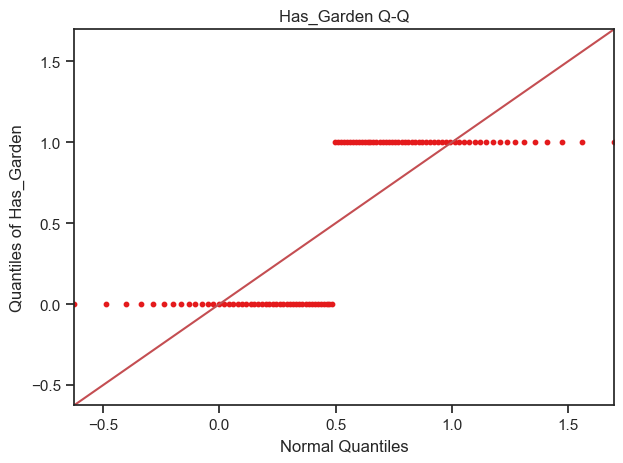

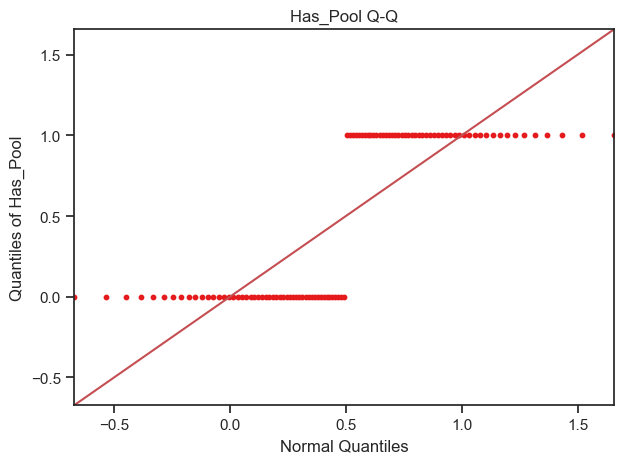

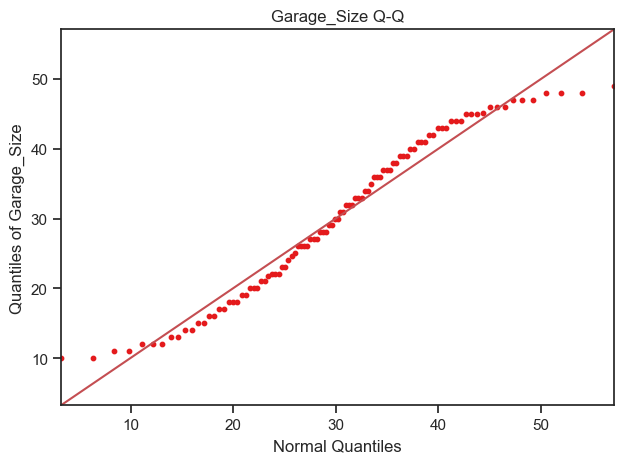

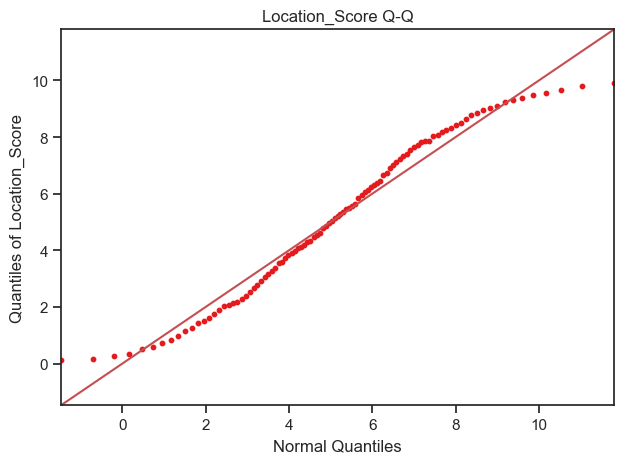

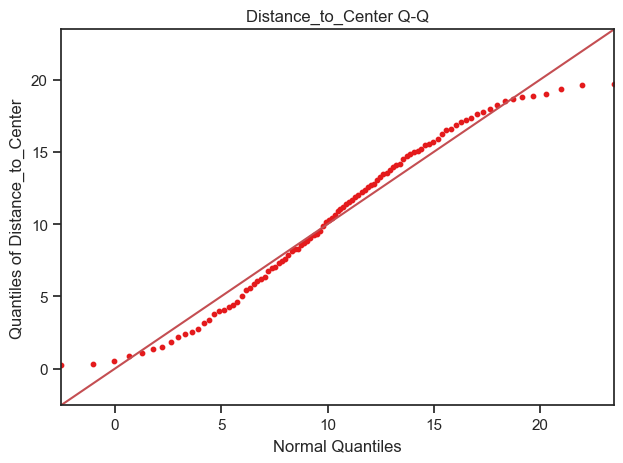

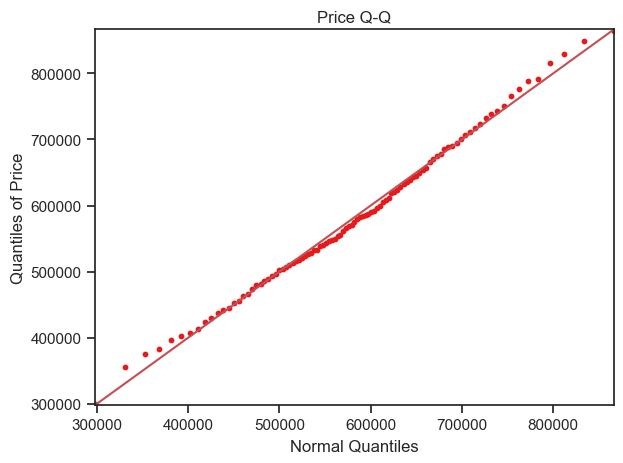

In [11]:
%matplotlib inline

for column in df.columns:

    # Get rid of any non-numerical columns.
    if pd.api.types.is_numeric_dtype(df[column]):

        # Drop missing values in case it causes problems
        values = df[column].dropna()

        # Fit a normal distribution to THIS column's own scale.
        mean, std = values.mean(), values.std()

        # Make 99 percentiles, evenly spaced.
        probs = np.linspace(0.01, 0.99, 99)

        # Copies dataprep's method. take the sample of the quantiles.
        sample_qntls = values.quantile(probs)

        # Theoretical quantiles: what a perfectly normal distribution with
        # the datas mean and std would look like at each %
        theory_qntls = norm.ppf(probs, mean, std)

        # Combine both sets to find a shared min/max.
        vals = np.concatenate([sample_qntls, theory_qntls])
        lo, hi = vals.min(), vals.max()
        fig, ax = plt.subplots()

        # Plot sample quantiles with theoretical quantiles.
        ax.scatter(theory_qntls, sample_qntls, s=10)

        # Draw a diagonal line.
        ax.plot([lo, hi], [lo, hi], color="r")

        # Force both axes to the same range. Makes the 45 degrees fixed.
        ax.set_xlim(lo, hi)
        ax.set_ylim(lo, hi)

        ax.set_title(f"{column} Q-Q")
        ax.set_xlabel("Normal Quantiles")
        ax.set_ylabel(f"Quantiles of {column}")

        plt.tight_layout()
        plt.show()

#### Check the Redundancy using Phik Matrix

In [12]:
df = pd.read_csv('real_estate_dataset.csv')
df = df.drop("ID", axis=1)

# compute phik-matrix values
phik_matrix = df.phik_matrix()

phik_matrix

interval columns not set, guessing: ['Square_Feet', 'Num_Bedrooms', 'Num_Bathrooms', 'Num_Floors', 'Year_Built', 'Has_Garden', 'Has_Pool', 'Garage_Size', 'Location_Score', 'Distance_to_Center', 'Price']


,Square_Feet,Num_Bedrooms,Num_Bathrooms,Num_Floors,Year_Built,Has_Garden,Has_Pool,Garage_Size,Location_Score,Distance_to_Center,Price
Square_Feet,1.000000,0.180314,0.000000,0.039252,0.076854,0.000000,0.000000,0.000000,0.000000,0.214970,0.501063
Num_Bedrooms,0.180314,1.000000,0.000000,0.032652,0.000000,0.000000,0.058882,0.125454,0.000000,0.103030,0.600625
Num_Bathrooms,0.000000,0.000000,1.000000,0.000000,0.155407,0.000000,0.000000,0.123840,0.000000,0.000000,0.189494
Num_Floors,0.039252,0.032652,0.000000,1.000000,0.000000,0.000000,0.000000,0.109753,0.042719,0.105741,0.158379
Year_Built,0.076854,0.000000,0.155407,0.000000,1.000000,0.000000,0.129798,0.000000,0.182347,0.000000,0.411584
Has_Garden,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.109859,0.066155,0.099507,0.000000,0.093670
Has_Pool,0.000000,0.058882,0.000000,0.000000,0.129798,0.109859,1.000000,0.000000,0.047300,0.040290,0.198028
Garage_Size,0.000000,0.125454,0.123840,0.109753,0.000000,0.066155,0.000000,1.000000,0.234171,0.000000,0.000000
Location_Score,0.000000,0.000000,0.000000,0.042719,0.182347,0.099507,0.047300,0.234171,1.000000,0.268984,0.000000
Distance_to_Center,0.214970,0.103030,0.000000,0.105741,0.000000,0.000000,0.040290,0.000000,0.268984,1.000000,0.098697


#### Visualize this using Heatmap

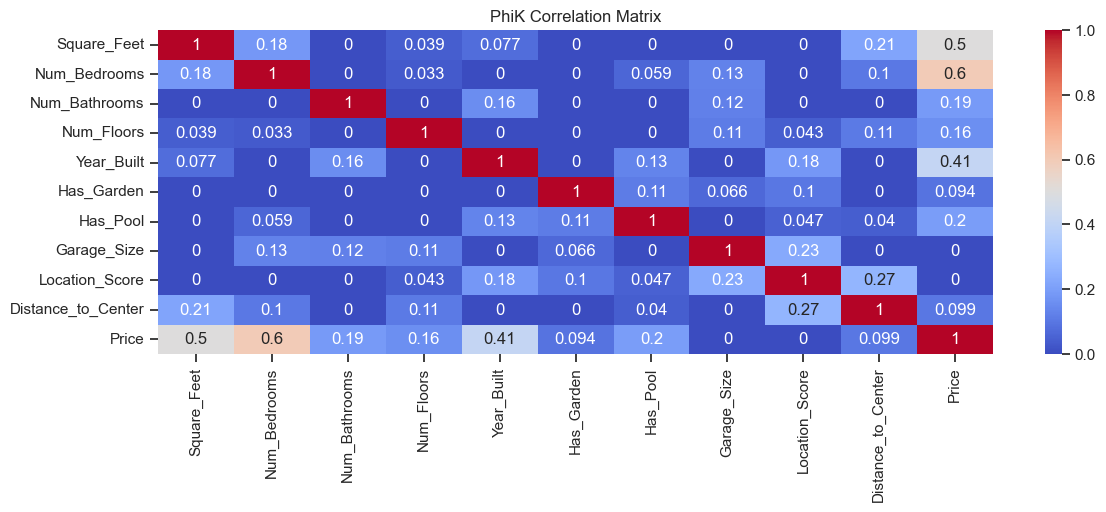

In [13]:
plt.figure(figsize=(12, 4))

sns.heatmap(
    phik_matrix,
    annot=True,
    cmap="coolwarm"
)

plt.title("PhiK Correlation Matrix")
plt.show()

#### Calculate VIF Test For the  Redundancy

In [14]:
df = pd.read_csv('real_estate_dataset.csv')
df = df.drop("ID", axis = 1)

# Save as a new csv for later use
df.to_csv("fixed_data.csv", index=False)
   

In [15]:
# need to install - pip install statsmodels
pd.set_option('display.float_format', lambda x: '%.1f' % x) 

import warnings
warnings.filterwarnings("ignore")

# Load the data
df = pd.read_csv('fixed_data.csv')

# perform X/y -split
# Everything EXCEPT target variable
X = df.drop('Price', axis = 1)

# Have only the target variable
y = df['Price']


# VIF Dataframe
vif_data = pd.DataFrame() 
vif_data["feature"] = X.columns 

# calculating VIF for each feature 
vif_data["VIF"] = [variance_inflation_factor(X.values, i)  for i in range(len(X.columns))] 

vif_data.sort_values(by="VIF", ascending=False)



,feature,VIF
9,Distance_to_Center,1.0
6,Has_Pool,1.0
0,Square_Feet,1.0
7,Garage_Size,1.0
3,Num_Floors,1.0
8,Location_Score,1.0
2,Num_Bathrooms,1.0
5,Has_Garden,1.0
1,Num_Bedrooms,1.0
4,Year_Built,1.0


### Detemine the Cardinality

In [16]:
# Find the columns which have unique values
df.nunique()

Square_Feet           500
Num_Bedrooms            5
Num_Bathrooms           3
Num_Floors              3
Year_Built            121
Has_Garden              2
Has_Pool                2
Garage_Size            40
Location_Score        500
Distance_to_Center    500
Price                 500
dtype: int64

### FInding Positive / Negative Trends

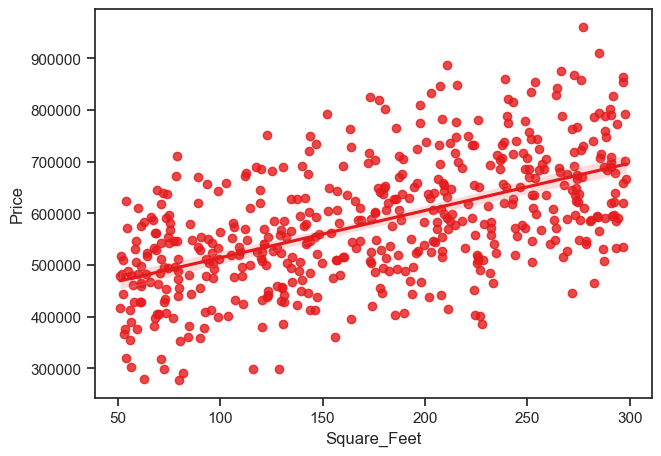

In [17]:
# We can use regression plots to see those trends
# price vs Square_Feet
sns.regplot(data=df, x="Square_Feet", y="Price")
plt.show()

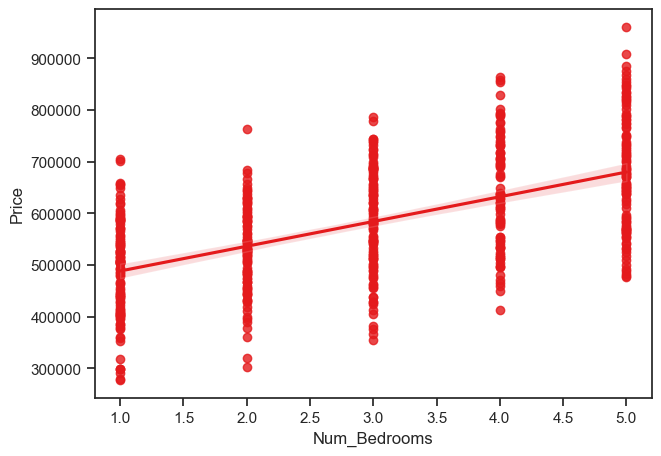

In [18]:
# Price vs Number_of_Bedroom
sns.regplot(data=df, x="Num_Bedrooms", y="Price")
plt.show()

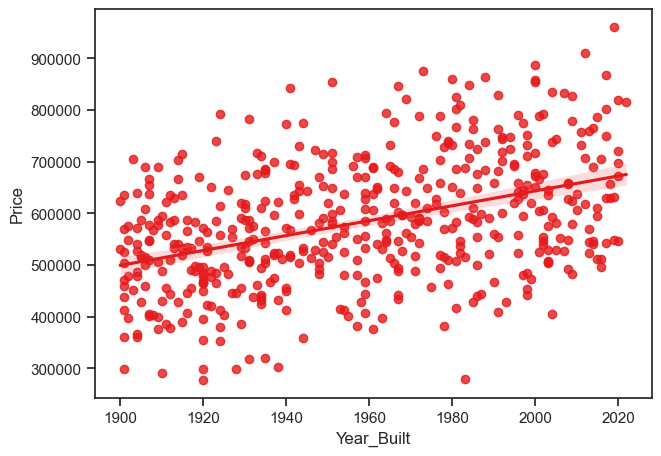

In [19]:
# Price vs Year_Built
sns.regplot(data=df, x="Year_Built", y="Price")
plt.show()

### Find the variabels that break the rules

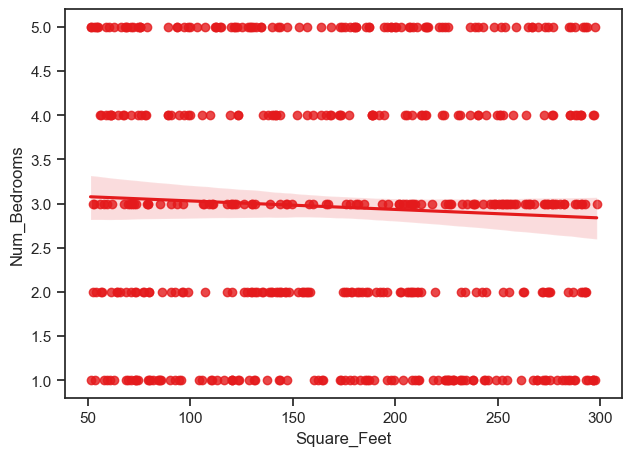

In [20]:
# We can choose those variables by using Phik matix visualization
# Visualize those varibales seprately with regression plots, to see their relationship
# Then we can relaize whether they have some surprice infroamtion
# Square_feet vs Num_Bedrooms
sns.regplot(data=df, x="Square_Feet", y="Num_Bedrooms")
plt.show()

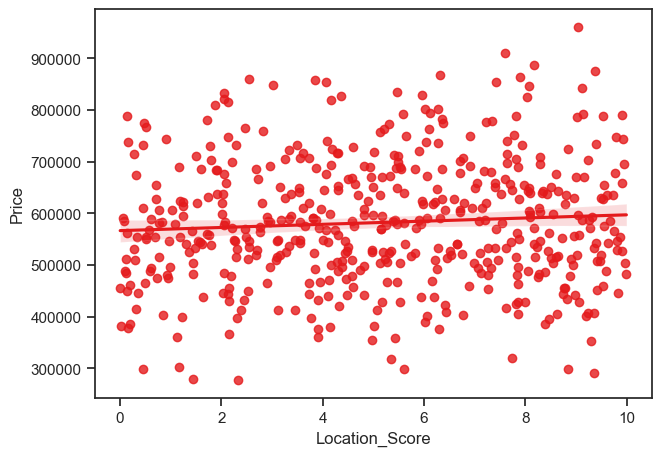

In [21]:
# Location_Score vs Price
sns.regplot(data=df, x="Location_Score", y="Price")
plt.show()

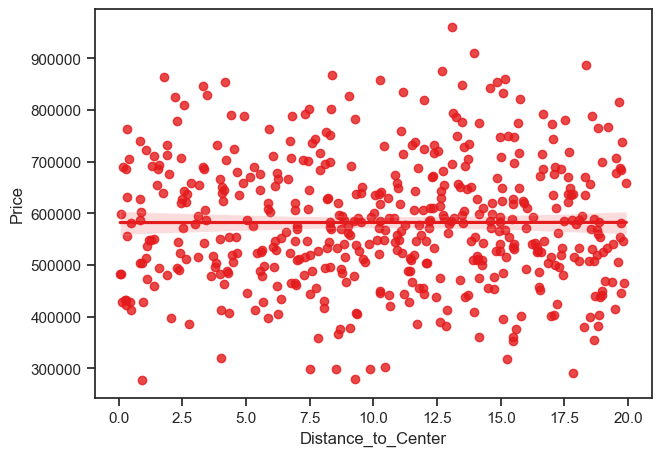

In [22]:
# Distance to center vs Price
sns.regplot(data=df, x="Distance_to_Center", y="Price")
plt.show()

### Check the noise or the outliers of the dataset using box plots


- #### Normally Dots beyond the whiskers are outliers, it may have some kind of a possible noise.
- #### We take meaningful variable which has continous values (more unique values) for visulaizations
- #### Binary encoded values or small counts of values are not taken in to the account

In [23]:
# Obtain the columns which has more continous values
# Chatgpt help to generate this code
numeric = df.select_dtypes("number")
cont_cols = [c for c in numeric if numeric[c].nunique() > 20]
print(cont_cols)

['Square_Feet', 'Year_Built', 'Garage_Size', 'Location_Score', 'Distance_to_Center', 'Price']


Square_Feet               Axes(0.08,0.511818;0.255882x0.368182)
Year_Built            Axes(0.387059,0.511818;0.255882x0.368182)
Garage_Size           Axes(0.694118,0.511818;0.255882x0.368182)
Location_Score                Axes(0.08,0.07;0.255882x0.368182)
Distance_to_Center        Axes(0.387059,0.07;0.255882x0.368182)
Price                     Axes(0.694118,0.07;0.255882x0.368182)
dtype: object

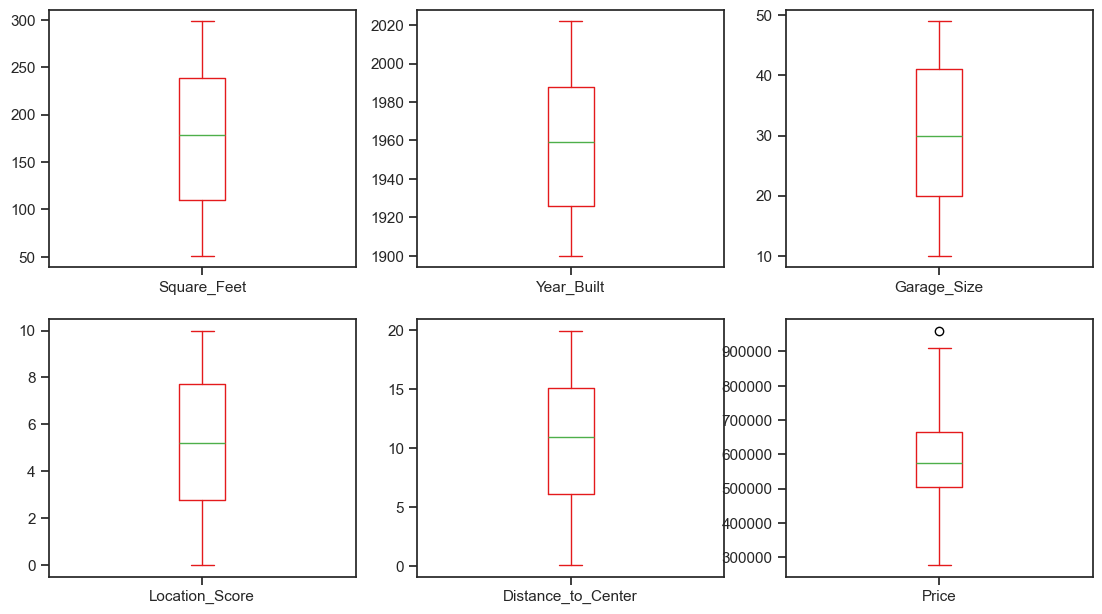

In [24]:
# Based on those columns we can generate the box plot
df[cont_cols].plot(kind="box", subplots=True, layout=(2, 3), figsize=(12, 7))

### Check whether Overlapping data have in Dataset


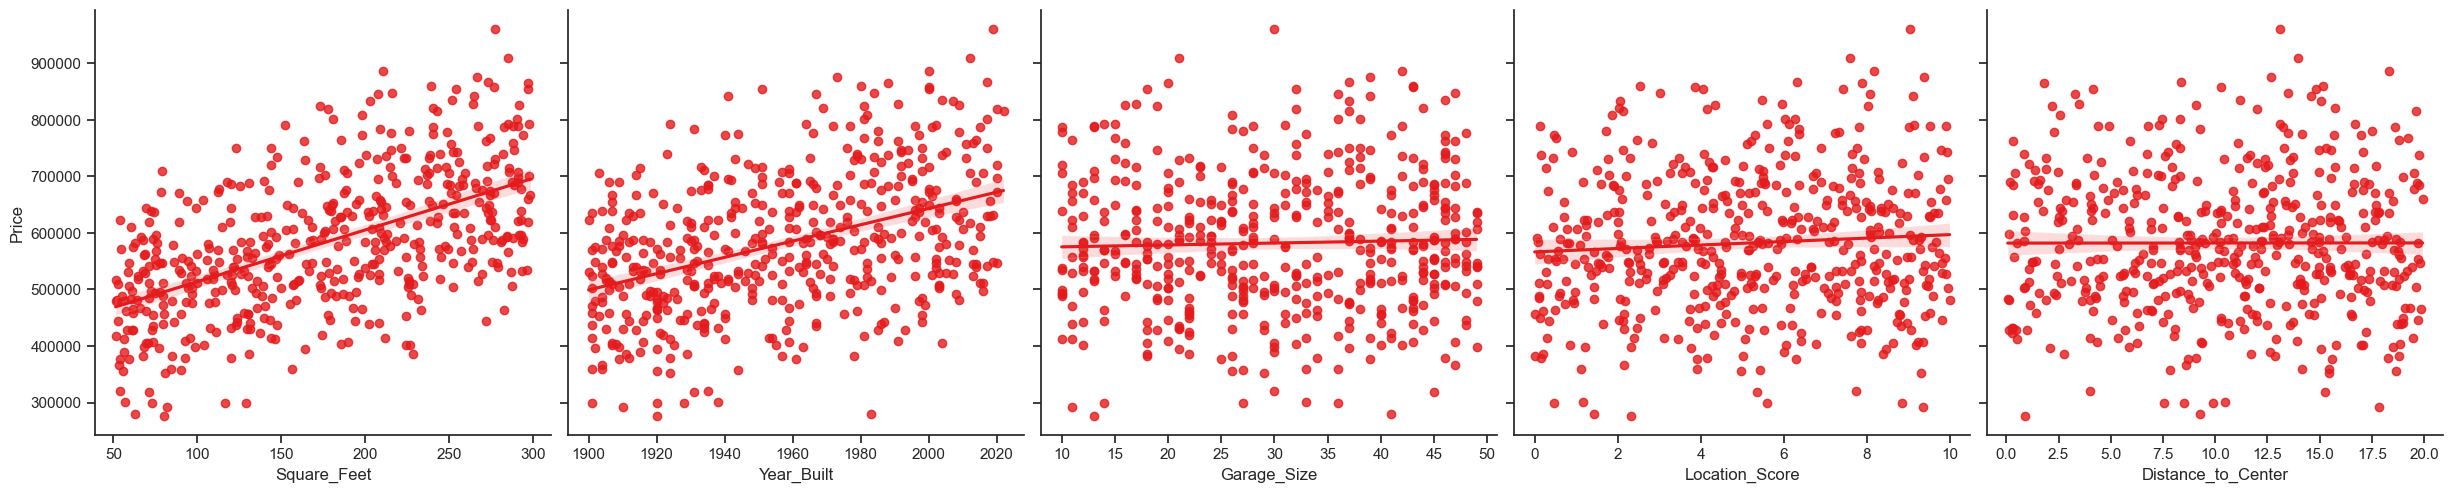

In [25]:
cols = ["Square_Feet", "Year_Built", "Garage_Size",
        "Location_Score", "Distance_to_Center"]

sns.pairplot(df, x_vars=cols, y_vars="Price", kind="reg",
             height=5, aspect=1)
plt.show()

### See the Noise or ouliers with the Z-score and visulaize them with other values


In [26]:
# load the dataset
df = pd.read_csv('fixed_data.csv')
# target variable
variable = "Price"
z_scores = stats.zscore(df[variable])

# Define a threshold for outliers
threshold = 2.5

# Detect outliers
outliers = df[np.abs(z_scores) > threshold]

print("Detected outliers using Z-score:")
outliers

Detected outliers using Z-score:


,Square_Feet,Num_Bedrooms,Num_Bathrooms,Num_Floors,Year_Built,Has_Garden,Has_Pool,Garage_Size,Location_Score,Distance_to_Center,Price
52,284.9,5,2,2,2012,1,1,21,7.6,13.9,909199.6
150,277.1,5,2,3,2019,1,1,30,9.0,13.1,960678.3


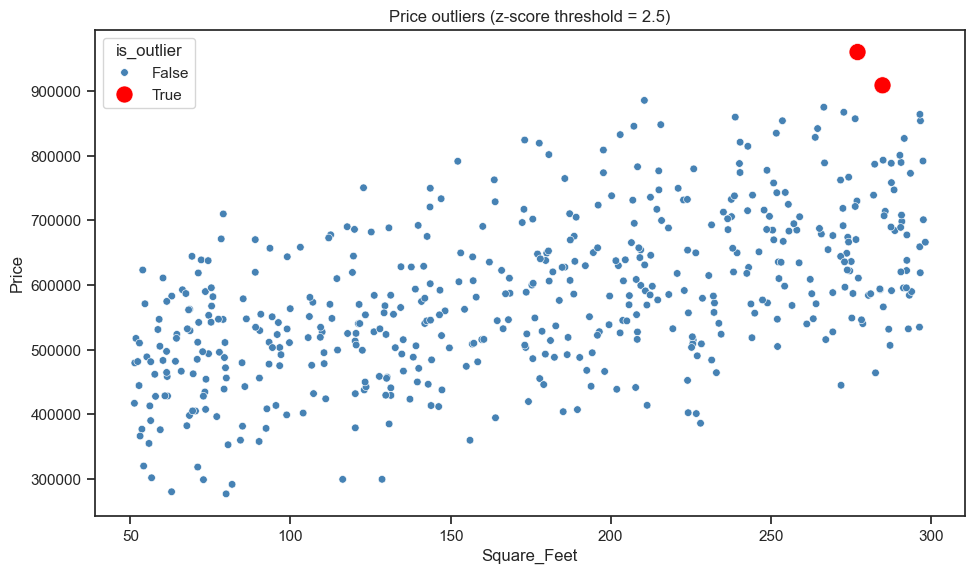

In [27]:
# Visualize the outlier 
# Chatgpt helps to hgenerate this code
# We use square_feert for the comparison because it is strongly related with the target variable of Price

df["is_outlier"] = np.abs(z_scores) > threshold

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="Square_Feet", y=variable,
                hue="is_outlier",
                palette={False: "steelblue", True: "red"},
                size="is_outlier", sizes={False: 30, True: 150})
plt.title(f"Price outliers (z-score threshold = {threshold})")
plt.show()

### Correlation & Associations


In [28]:
# Determine the correlation and visualize using heat-map
# The variables highly related to the Target value of Price
df.corr(numeric_only=True)['Price'].sort_values(ascending=False)

Price                1.0
Num_Bedrooms         0.6
Square_Feet          0.6
Year_Built           0.4
is_outlier           0.2
Num_Floors           0.2
Num_Bathrooms        0.2
Has_Pool             0.1
Has_Garden           0.1
Location_Score       0.1
Garage_Size          0.0
Distance_to_Center   0.0
Name: Price, dtype: float64

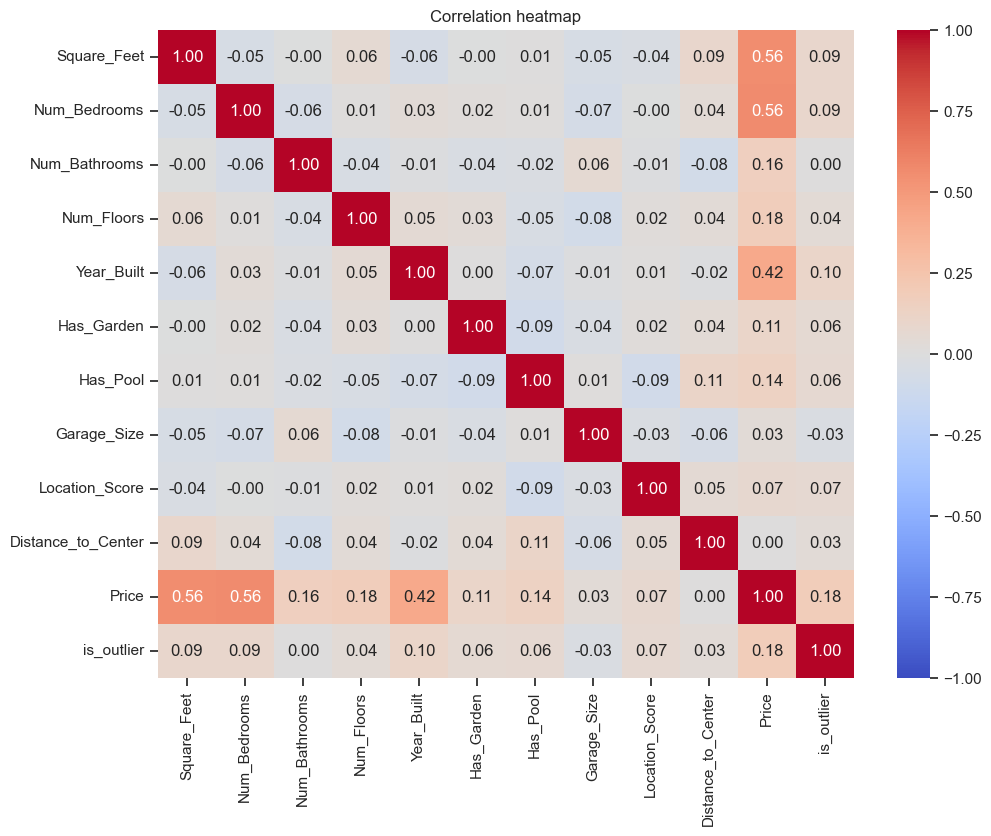

In [29]:
# Visualize using heat-map
corr = df.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation heatmap")
plt.show()


### Determine which features are more important with the target variable

#### Use Select-Best for this

In [30]:
# Load the dataset
df = pd.read_csv('fixed_data.csv')

# Perform X-Y Split
X = df.drop("Price", axis = 1)

# have only the target variable here (dependent variable)
y = df["Price"]

# convert all continuous variables to integer,
# and convert all negative numbers to 0
X_cat = X.astype(int)
X_cat = X_cat.clip(lower=0)

chi_2_features = SelectKBest(chi2, k=len(X_cat.columns))

# fit our data to the SelectKBest
best_features = chi_2_features.fit(X_cat,y.astype(int))

# use decimal format in table print later
pd.options.display.float_format = '{:.2f}'.format

# wrap it up, and show the results
df_features = pd.DataFrame(best_features.scores_)
df_columns = pd.DataFrame(X_cat.columns)
f_scores = pd.concat([df_columns,df_features],axis=1)
f_scores.columns = ['Features','Score']
f_scores.sort_values(by='Score',ascending=False)

,Features,Score
0,Square_Feet,15975.67
7,Garage_Size,2218.59
9,Distance_to_Center,1547.28
8,Location_Score,850.95
1,Num_Bedrooms,350.28
4,Year_Built,321.09
6,Has_Pool,254.00
5,Has_Garden,232.00
2,Num_Bathrooms,169.89
3,Num_Floors,163.62


### Check what are the variablews need to keep 
#### We can use RFE or MI for this 

In [ ]:
# import modules
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import RFE, mutual_info_regression, mutual_info_classif
from sklearn.model_selection import train_test_split

# Load the dataset
df = pd.read_csv('fixed_data.csv')

# Define target variable
TARGET_VARIABLE = "Price"
#  typical X/y -split
X = df.drop(TARGET_VARIABLE, axis=1)
y = df[TARGET_VARIABLE]

# define model
model = RandomForestRegressor()

# create RFE, place the model and choose number of optimal variables
rfe = RFE(estimator=model, n_features_to_select=7)

# fit the RFE model with our data
rfe.fit(X, y)

# get rankings and results
rankings = rfe.ranking_
support = rfe.support_

# build a DataFrame to wrap up result for easier inspection
results_df = pd.DataFrame({
    "Feature": X.columns,
    "Ranking": rankings,
    "Selected": support
}).sort_values(by="Ranking")

# Show the results
results_df

,Feature,Ranking,Selected
0,Square_Feet,1,True
1,Num_Bedrooms,1,True
2,Num_Bathrooms,1,True
4,Year_Built,1,True
7,Garage_Size,1,True
8,Location_Score,1,True
9,Distance_to_Center,1,True
6,Has_Pool,2,False
3,Num_Floors,3,False
5,Has_Garden,4,False
